LOADING REAL DATASET

Dataset loaded successfully!

Number of rows: 569
Number of columns: 32

First 10 rows:
   mean radius  mean texture  mean perimeter  mean area  mean smoothness  \
0        17.99         10.38          122.80     1001.0          0.11840   
1        20.57         17.77          132.90     1326.0          0.08474   
2        19.69         21.25          130.00     1203.0          0.10960   
3        11.42         20.38           77.58      386.1          0.14250   
4        20.29         14.34          135.10     1297.0          0.10030   
5        12.45         15.70           82.57      477.1          0.12780   
6        18.25         19.98          119.60     1040.0          0.09463   
7        13.71         20.83           90.20      577.9          0.11890   
8        13.00         21.82           87.50      519.8          0.12730   
9        12.46         24.04           83.97      475.9          0.11860   

   mean compactness  mean concavity  mean concave poi

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>


PREPARING DATA

Features (X): (569, 30)
Target (y): (569,)

Training data: (455, 30)
Testing data: (114, 30)

BAGGING - RANDOM FOREST

Random Forest Results:
Accuracy : 0.9561
Precision: 0.9589
Recall   : 0.9722
F1-Score : 0.9655

BOOSTING - ADABOOST

AdaBoost Results:
Accuracy : 0.9561
Precision: 0.9467
Recall   : 0.9861
F1-Score : 0.966

PERFORMANCE COMPARISON
   Metric  Random Forest (Bagging)  AdaBoost (Boosting)
 Accuracy                 0.956140             0.956140
Precision                 0.958904             0.946667
   Recall                 0.972222             0.986111
 F1-Score                 0.965517             0.965986

RANDOM FOREST - BAGGING
              precision    recall  f1-score   support

   Malignant       0.95      0.93      0.94        42
      Benign       0.96      0.97      0.97        72

    accuracy                           0.96       114
   macro avg       0.96      0.95      0.95       114
weighted avg       0.96      0.96      0.96       114


A

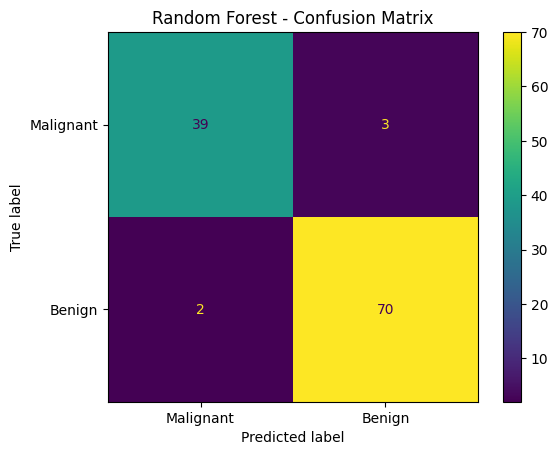


CONFUSION MATRIX - ADABOOST
[[38  4]
 [ 1 71]]


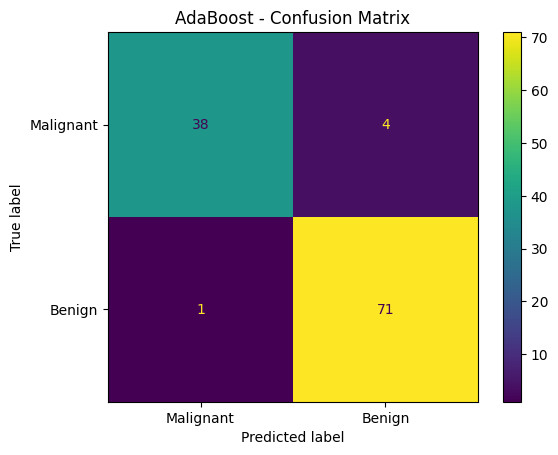

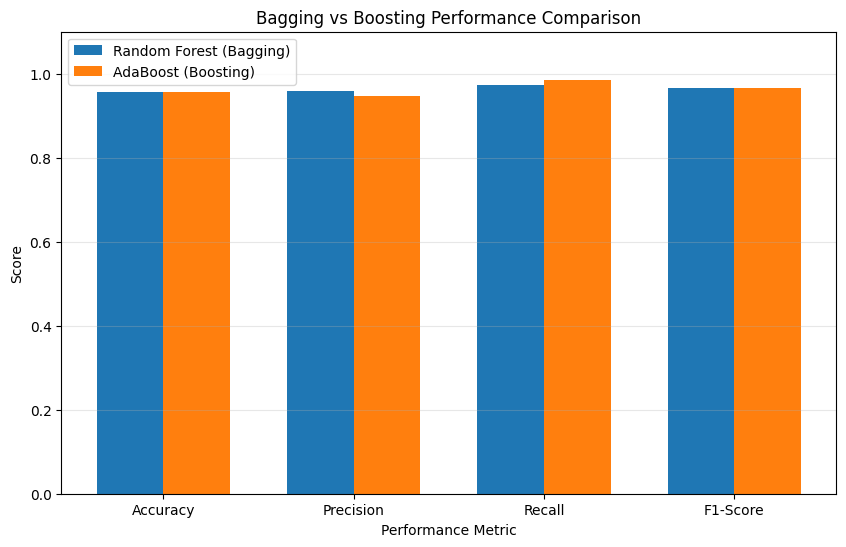


FINAL RESULT

Best performing model: AdaBoost (Boosting)
Best accuracy: 95.61 %

Random Forest Accuracy: 95.61 %
AdaBoost Accuracy: 95.61 %

Conclusion:
The supervised Breast Cancer Wisconsin dataset was classified using Random Forest (Bagging) and AdaBoost (Boosting). The performance of both models was compared using accuracy, precision, recall and F1-score.
AdaBoost achieved better performance than Random Forest on this dataset.

Comparison results saved as:
bagging_boosting_comparison.csv


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>


EXPERIMENT COMPLETED SUCCESSFULLY


In [1]:
# ============================================================
# BAGGING AND BOOSTING CLASSIFICATION
# REAL DATASET: BREAST CANCER WISCONSIN (DIAGNOSTIC)
# ============================================================

# ------------------------------------------------------------
# 1. IMPORT LIBRARIES
# ------------------------------------------------------------

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.datasets import load_breast_cancer

from sklearn.model_selection import train_test_split

from sklearn.ensemble import RandomForestClassifier, AdaBoostClassifier

from sklearn.tree import DecisionTreeClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

from google.colab import files


# ============================================================
# 2. LOAD REAL DATASET
# ============================================================

print("=" * 60)
print("LOADING REAL DATASET")
print("=" * 60)

data = load_breast_cancer()

# Create DataFrame using the actual feature names
df = pd.DataFrame(
    data.data,
    columns=data.feature_names
)

# Add target column
df["target"] = data.target

# Add readable target names
df["diagnosis"] = df["target"].map({
    0: "Malignant",
    1: "Benign"
})

print("\nDataset loaded successfully!")

print("\nNumber of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

print("\nFirst 10 rows:")
print(df.head(10))


# ============================================================
# 3. UNDERSTAND THE DATASET
# ============================================================

print("\n" + "=" * 60)
print("DATASET INFORMATION")
print("=" * 60)

print("\nTarget distribution:")
print(df["diagnosis"].value_counts())

print("\nDataset shape:")
print(df.shape)

print("\nFeature names:")
for feature in data.feature_names:
    print("-", feature)


# ============================================================
# 4. SAVE REAL DATASET AS CSV
# ============================================================

dataset_filename = "breast_cancer_real_dataset.csv"

df.to_csv(dataset_filename, index=False)

print("\nDataset saved as:")
print(dataset_filename)

# Download dataset
files.download(dataset_filename)


# ============================================================
# 5. PREPARE DATA FOR MACHINE LEARNING
# ============================================================

# X = input features
# y = target

X = df[data.feature_names]
y = df["target"]

print("\n" + "=" * 60)
print("PREPARING DATA")
print("=" * 60)

print("\nFeatures (X):", X.shape)
print("Target (y):", y.shape)


# ============================================================
# 6. SPLIT DATA INTO TRAINING AND TESTING
# ============================================================

# 80% training
# 20% testing

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("\nTraining data:", X_train.shape)
print("Testing data:", X_test.shape)


# ============================================================
# 7. BAGGING MODEL - RANDOM FOREST
# ============================================================

print("\n" + "=" * 60)
print("BAGGING - RANDOM FOREST")
print("=" * 60)

random_forest = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

# Train Random Forest
random_forest.fit(X_train, y_train)

# Predict test data
y_pred_rf = random_forest.predict(X_test)

# Calculate metrics
rf_accuracy = accuracy_score(y_test, y_pred_rf)
rf_precision = precision_score(y_test, y_pred_rf)
rf_recall = recall_score(y_test, y_pred_rf)
rf_f1 = f1_score(y_test, y_pred_rf)

print("\nRandom Forest Results:")

print("Accuracy :", round(rf_accuracy, 4))
print("Precision:", round(rf_precision, 4))
print("Recall   :", round(rf_recall, 4))
print("F1-Score :", round(rf_f1, 4))


# ============================================================
# 8. BOOSTING MODEL - ADABOOST
# ============================================================

print("\n" + "=" * 60)
print("BOOSTING - ADABOOST")
print("=" * 60)

# Simple decision tree used as the base learner
base_tree = DecisionTreeClassifier(
    max_depth=1,
    random_state=42
)

adaboost = AdaBoostClassifier(
    estimator=base_tree,
    n_estimators=100,
    random_state=42
)

# Train AdaBoost
adaboost.fit(X_train, y_train)

# Predict test data
y_pred_ada = adaboost.predict(X_test)

# Calculate metrics
ada_accuracy = accuracy_score(y_test, y_pred_ada)
ada_precision = precision_score(y_test, y_pred_ada)
ada_recall = recall_score(y_test, y_pred_ada)
ada_f1 = f1_score(y_test, y_pred_ada)

print("\nAdaBoost Results:")

print("Accuracy :", round(ada_accuracy, 4))
print("Precision:", round(ada_precision, 4))
print("Recall   :", round(ada_recall, 4))
print("F1-Score :", round(ada_f1, 4))


# ============================================================
# 9. PERFORMANCE COMPARISON
# ============================================================

comparison = pd.DataFrame({
    "Metric": [
        "Accuracy",
        "Precision",
        "Recall",
        "F1-Score"
    ],

    "Random Forest (Bagging)": [
        rf_accuracy,
        rf_precision,
        rf_recall,
        rf_f1
    ],

    "AdaBoost (Boosting)": [
        ada_accuracy,
        ada_precision,
        ada_recall,
        ada_f1
    ]
})

print("\n" + "=" * 60)
print("PERFORMANCE COMPARISON")
print("=" * 60)

print(comparison.to_string(index=False))


# ============================================================
# 10. RANDOM FOREST CLASSIFICATION REPORT
# ============================================================

print("\n" + "=" * 60)
print("RANDOM FOREST - BAGGING")
print("=" * 60)

print(
    classification_report(
        y_test,
        y_pred_rf,
        target_names=["Malignant", "Benign"]
    )
)


# ============================================================
# 11. ADABOOST CLASSIFICATION REPORT
# ============================================================

print("\n" + "=" * 60)
print("ADABOOST - BOOSTING")
print("=" * 60)

print(
    classification_report(
        y_test,
        y_pred_ada,
        target_names=["Malignant", "Benign"]
    )
)


# ============================================================
# 12. CONFUSION MATRIX - RANDOM FOREST
# ============================================================

print("\n" + "=" * 60)
print("CONFUSION MATRIX - RANDOM FOREST")
print("=" * 60)

cm_rf = confusion_matrix(y_test, y_pred_rf)

print(cm_rf)

disp_rf = ConfusionMatrixDisplay(
    confusion_matrix=cm_rf,
    display_labels=["Malignant", "Benign"]
)

disp_rf.plot()
plt.title("Random Forest - Confusion Matrix")
plt.show()


# ============================================================
# 13. CONFUSION MATRIX - ADABOOST
# ============================================================

print("\n" + "=" * 60)
print("CONFUSION MATRIX - ADABOOST")
print("=" * 60)

cm_ada = confusion_matrix(y_test, y_pred_ada)

print(cm_ada)

disp_ada = ConfusionMatrixDisplay(
    confusion_matrix=cm_ada,
    display_labels=["Malignant", "Benign"]
)

disp_ada.plot()
plt.title("AdaBoost - Confusion Matrix")
plt.show()


# ============================================================
# 14. BAR GRAPH - PERFORMANCE COMPARISON
# ============================================================

metrics = [
    "Accuracy",
    "Precision",
    "Recall",
    "F1-Score"
]

rf_scores = [
    rf_accuracy,
    rf_precision,
    rf_recall,
    rf_f1
]

ada_scores = [
    ada_accuracy,
    ada_precision,
    ada_recall,
    ada_f1
]

x = np.arange(len(metrics))
width = 0.35

plt.figure(figsize=(10, 6))

plt.bar(
    x - width/2,
    rf_scores,
    width,
    label="Random Forest (Bagging)"
)

plt.bar(
    x + width/2,
    ada_scores,
    width,
    label="AdaBoost (Boosting)"
)

plt.xticks(x, metrics)
plt.ylabel("Score")
plt.xlabel("Performance Metric")
plt.title("Bagging vs Boosting Performance Comparison")

plt.ylim(0, 1.1)

plt.legend()
plt.grid(axis="y", alpha=0.3)

plt.show()


# ============================================================
# 15. FIND THE BEST MODEL
# ============================================================

if rf_accuracy > ada_accuracy:
    best_model = "Random Forest (Bagging)"
    best_accuracy = rf_accuracy
else:
    best_model = "AdaBoost (Boosting)"
    best_accuracy = ada_accuracy


# ============================================================
# 16. FINAL RESULT
# ============================================================

print("\n" + "=" * 60)
print("FINAL RESULT")
print("=" * 60)

print("\nBest performing model:", best_model)

print(
    "Best accuracy:",
    round(best_accuracy * 100, 2),
    "%"
)

print("\nRandom Forest Accuracy:",
      round(rf_accuracy * 100, 2), "%")

print("AdaBoost Accuracy:",
      round(ada_accuracy * 100, 2), "%")


print("\nConclusion:")
print(
    "The supervised Breast Cancer Wisconsin dataset was classified "
    "using Random Forest (Bagging) and AdaBoost (Boosting). "
    "The performance of both models was compared using accuracy, "
    "precision, recall and F1-score."
)

if rf_accuracy > ada_accuracy:
    print(
        "Random Forest achieved better performance than AdaBoost "
        "on this dataset."
    )
else:
    print(
        "AdaBoost achieved better performance than Random Forest "
        "on this dataset."
    )


# ============================================================
# 17. SAVE RESULTS
# ============================================================

comparison_filename = "bagging_boosting_comparison.csv"

comparison.to_csv(comparison_filename, index=False)

print("\nComparison results saved as:")
print(comparison_filename)

files.download(comparison_filename)

print("\n============================================================")
print("EXPERIMENT COMPLETED SUCCESSFULLY")
print("============================================================")